<!--
Copyright © 2026 The Trustees of Indiana University and contributors.
This work is licensed under the Creative Commons Attribution-NonCommercial 4.0 International License (CC BY-NC 4.0).
You may use, share, and adapt this work for non-commercial purposes, subject to the terms of the license and appropriate attribution.
See the LICENSE file in the root of this repository for the full license terms.
https://creativecommons.org/licenses/by-nc/4.0/
-->

# Lurker Ratio Report

This notebook is a report notebook for the CSV outputs generated by `lurker_ratio_prep.py`.
Run top to bottom after the prep step; each section focuses on a different view of the data.
Each plot is annotated with its numerator, denominator, and inclusion rule.

This version compares three prep outputs side by side:
- Original
- Ignore 1st week of lurking
- Ignore 1st week of all activity

**Required before running this notebook**: from `analyses/calibration/user/lurker_ratio/`, run `python lurker_ratio_prep.py`.


## Research definitions of user types

This report uses three user-type definitions consistently across the calibration. The raw output columns still use the implementation term `seen_users`; in the text below, that same population is described as **Active Users**.

- **Active Users**: users who have logged in and performed at least one observed action in the dataset. This is the denominator population for the lurker-ratio calibration.
- **Non-Lurkers**: Active Users who have performed at least one action that is visible to others. In this report, visible actions are qualifying `create` events for posts, replies, quotes, reposts, or likes.
- **Lurkers**: Active Users who have performed observed actions, but only actions that are not visible to others. In the metric, they are the Active Users who have not yet satisfied the Non-Lurker rule.

The core calibration metric is:

`lurker_ratio = Lurkers / Active Users`

A lower ratio means more Active Users have become Non-Lurkers; a higher ratio means more Active Users remain Lurkers.


## Folder placement

- **Current location**: `analyses/calibration/user/lurker_ratio/`
- **Prep script**: `lurker_ratio_prep.py`
- **Design reference**: `lurker_ratio_reordered.ipynb`


## 1) Data used

Describe the empirical data source(s) in enough detail for a future reader to obtain or reproduce it.

- **Dataset name or source**: Bluesky Firehose
- **Time range**: `2023-09` to `2026-04`
- **Access / documentation link**: Data collection was done with `osome-bluesky-streamer`; archive access is managed by OSoMe IU.
- **Raw files / tables used**: Raw compressed Firehose archives consumed by `lurker_ratio_prep.py`, then `data/output/reports/user_state.csv`, baseline `full_period_cumulative.csv` / `lurker_ratio_daily.csv` / `lurker_ratio_monthly.csv`, plus the matching `ignore_first_week_lurking_*` and `ignore_first_week_all_activity_*` CSV families.
- **Preprocessing steps**: `lurker_ratio_prep.py` recursively discovers raw files, applies the coverage filter, computes exact per-user state, and writes report-ready CSVs.
- **Day coverage rule**: Keep days with at least `22` hours of coverage, matching the prep script default.
- **Definitions used in this report**: see **Research definitions of user types** above. Implementation columns named `seen_users` correspond to **Active Users** in the research framing.
- **Implementation note**: Replies and quotes are included through `app.bsky.feed.post` creates, likes are included with `app.bsky.feed.like`, while reposts are included through `app.bsky.feed.repost` creates.
- **Required step**: `python lurker_ratio_prep.py` must be run before this report notebook.


In [1]:
from pathlib import Path

import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd


def resolve_reports_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / "data" / "output" / "reports",
        cwd / "analyses" / "calibration" / "user" / "lurker_ratio" / "data" / "output" / "reports",
    ]
    for parent in [cwd, *cwd.parents]:
        candidates.append(parent / "analyses" / "calibration" / "user" / "lurker_ratio" / "data" / "output" / "reports")
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if candidate.exists():
            return candidate
    return (cwd / "data" / "output" / "reports").resolve()


def add_definition_box(ax, lines, x=0.02, y=0.98, ha="left", va="top"):
    ax.text(
        x, y, "\n".join(lines), transform=ax.transAxes, ha=ha, va=va, fontsize=12,
        bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "0.7", "boxstyle": "round,pad=0.35"},
    )


REPORTS_DIR = resolve_reports_dir()
VARIANT_SPECS = {
    "baseline": {"label": "Original", "prefix": "", "user_suffix": ""},
    "ignore_first_week_lurking": {
        "label": "Ignore 1st week of lurking",
        "prefix": "ignore_first_week_lurking_",
        "user_suffix": "_ignore_first_week_lurking",
    },
    "ignore_first_week_all_activity": {
        "label": "Ignore 1st week of all activity",
        "prefix": "ignore_first_week_all_activity_",
        "user_suffix": "_ignore_first_week_all_activity",
    },
}
variant_colors = {"baseline": "C0", "ignore_first_week_lurking": "C1", "ignore_first_week_all_activity": "C2"}

USER_STATE_PATH = REPORTS_DIR / "user_state.csv"
if not USER_STATE_PATH.exists():
    raise FileNotFoundError(f"Missing prep output: {USER_STATE_PATH}")

user_date_cols = [
    "first_seen_day", "first_non_lurker_day", "last_seen_day", "last_non_lurker_day",
    "first_seen_day_ignore_first_week_lurking", "first_non_lurker_day_ignore_first_week_lurking",
    "last_seen_day_ignore_first_week_lurking", "last_non_lurker_day_ignore_first_week_lurking",
    "first_seen_day_ignore_first_week_all_activity", "first_non_lurker_day_ignore_first_week_all_activity",
    "last_seen_day_ignore_first_week_all_activity", "last_non_lurker_day_ignore_first_week_all_activity",
]
users_preview = pd.read_csv(USER_STATE_PATH, nrows=5)
available_user_date_cols = [c for c in user_date_cols if c in users_preview.columns]
users = pd.read_csv(USER_STATE_PATH, parse_dates=available_user_date_cols)

required_user_cols = {
    "author", "first_seen_day", "first_non_lurker_day", "last_seen_day", "last_non_lurker_day",
    "seen_day_count", "non_lurker_day_count", "first_non_lurker_day_ignore_first_week_lurking",
    "first_seen_day_ignore_first_week_all_activity", "first_non_lurker_day_ignore_first_week_all_activity",
}
missing_user_cols = sorted(required_user_cols - set(users.columns))
if missing_user_cols:
    raise ValueError(f"user_state.csv is missing required columns: {missing_user_cols}")

variant_frames = {}
schema_rows = []
for variant_name, spec in VARIANT_SPECS.items():
    prefix = spec["prefix"]
    cumulative_path = REPORTS_DIR / f"{prefix}full_period_cumulative.csv"
    daily_path = REPORTS_DIR / f"{prefix}lurker_ratio_daily.csv"
    monthly_path = REPORTS_DIR / f"{prefix}lurker_ratio_monthly.csv"
    for path in [cumulative_path, daily_path, monthly_path]:
        if not path.exists():
            raise FileNotFoundError(f"Missing prep output: {path}")
    cumulative_df = pd.read_csv(cumulative_path, parse_dates=["day"])
    daily_df = pd.read_csv(daily_path, parse_dates=["day"])
    monthly_df = pd.read_csv(monthly_path, parse_dates=["month"])
    for name, df, required in [
        (cumulative_path.name, cumulative_df, {"day", "seen_users", "non_lurkers", "lurkers", "lurker_ratio"}),
        (daily_path.name, daily_df, {"day", "window_size", "seen_users", "non_lurkers", "lurkers", "lurker_ratio"}),
        (monthly_path.name, monthly_df, {"month", "window_size", "avg_seen_users", "avg_non_lurkers", "avg_lurkers", "lurker_ratio"}),
    ]:
        missing = sorted(required - set(df.columns))
        if missing:
            raise ValueError(f"{name} is missing required columns: {missing}")
    variant_frames[variant_name] = {"cumulative": cumulative_df, "daily": daily_df, "monthly": monthly_df}
    schema_rows.extend([
        {"variant": spec["label"], "dataset": "cumulative", "rows": len(cumulative_df), "columns": ", ".join(cumulative_df.columns)},
        {"variant": spec["label"], "dataset": "daily", "rows": len(daily_df), "columns": ", ".join(daily_df.columns)},
        {"variant": spec["label"], "dataset": "monthly", "rows": len(monthly_df), "columns": ", ".join(monthly_df.columns)},
    ])

cumulative = variant_frames["baseline"]["cumulative"]
daily = variant_frames["baseline"]["daily"]
monthly = variant_frames["baseline"]["monthly"]


## 2) New feature contribution

Explain what new feature this calibration adds and where it lives in the codebase.

- **Component**: field `user.activity.lurker_sample_rate` in `libs/simsom/config/default_simulator_config.jsonc`
- **What it adds**: A prep-backed empirical estimate of the share of **Active Users** who remain **Lurkers** instead of becoming **Non-Lurkers**.
- **Code location**: This notebook is report-only; the pipeline logic lives in `analyses/calibration/user/lurker_ratio/lurker_ratio_prep.py`.
- **Design rationale**: The updated report uses exact per-user first-seen and first-non-lurker days from `lurker_ratio_prep.py`, and the result views follow `lurker_ratio_reordered.ipynb`.


## 2b) References & provenance

Make the calibration traceable to specific code and design. Complete one or more of items below.

- **Primary pipeline source**: `analyses/calibration/user/lurker_ratio/lurker_ratio_prep.py`
- **Latest design / output reference**: `analyses/calibration/user/lurker_ratio/lurker_ratio_reordered.ipynb`
- **Generated report inputs**: `data/output/reports/user_state.csv`, baseline `full_period_cumulative.csv` / `lurker_ratio_daily.csv` / `lurker_ratio_monthly.csv`, plus the matching `ignore_first_week_lurking_*` and `ignore_first_week_all_activity_*` files.


## 3) Analysis / calibration method

Document how the data are transformed into model parameters or behaviors.

- **Features extracted**: per-user first/last Active User day and first Non-Lurker day, cumulative lurker ratio, monthly cohort conversion curves, and sliding-window lurker ratios.
- **Pipeline**: `lurker_ratio_prep.py` recursively discovers raw files, applies the coverage filter, computes exact shard-local user state, and writes report-ready CSVs.
- **Active User rule**: a user enters the denominator after logging in and performing at least one observed action in the dataset. The implementation column for this count is `seen_users`.
- **Non-Lurker rule**: an Active User becomes a Non-Lurker after any visible qualifying `create` event: post, reply, quote, repost, or like.
- **Lurker rule**: an Active User remains a Lurker until they satisfy the Non-Lurker rule; their observed activity is limited to actions that are not visible to others.
- **Variant definitions**:
  - **Original**: no burn-in filter.
  - **Ignore 1st week of lurking**: removes only first-week Active User days that are lurking-only; first-week Non-Lurker days remain counted.
  - **Ignore 1st week of all activity**: removes both Active User and Non-Lurker activity from each user's first 7 days.
- **Metric definitions**: `active_users(t)` / `seen_users(t)` counts users with `first_seen_day <= t`; `non_lurkers(t)` counts Active Users with `first_non_lurker_day <= t`; `lurkers(t) = active_users(t) - non_lurkers(t)`; `lurker_ratio(t) = lurkers(t) / active_users(t)`.
- **Sliding window setup**: for trailing window `W`, `active_users_W(t)` means users with any event in `[t-W+1, t]`; `non_lurkers_W(t)` means users with at least one qualifying visible `create` in `[t-W+1, t]`; `lurkers_W(t) = active_users_W(t) - non_lurkers_W(t)`.
- **Validation**: monthly cohort convergence, lurker ratio over time on a fixed set of users, cumulative lurker ratio, sliding-window lurker ratio, and Active User growth sanity checks.


## 3b) Reproduction steps

Provide minimal steps so a new researcher can reproduce the analysis.

1. Ensure the Bluesky Firehose archive is available under the data path you intend to analyze. Default path is `./data/raw/`
2. Run `python lurker_ratio_prep.py`. This step is required before the report notebook can run.
3. If needed, pass prep arguments such as `--data-path`, `--output-dir`, `--analysis-start-day`, `--analysis-end-day`, or `--windows`.
4. Run this notebook top-to-bottom to review the generated report tables and plots.


## 4) Results

Summarize the outcome and attach key plots/tables. If large, do not upload to repo.

- **Outputs / artifacts**: In-notebook tables and plots driven by the generated CSVs.
- **Where results are saved**: In-notebook, using the prep outputs under `data/output/reports/`.
- **Key takeaways**: The report compares the original series against the two first-week-filtered variants on cohort convergence, fixed-user lurker ratio, cumulative lurker ratio, trailing-window lurker ratio, and supporting count tables.


**Lurker report outputs**

- Monthly cohort lurker convergence since first Active User date, compared across all three variants.
- Lurker ratio over time on a fixed set of Active Users, compared across all three variants.
- Cumulative lurker ratio over time, compared across all three variants.
- Sliding-window lurker ratio for `1`, `7`, `30`, and `60` day windows, compared across all three variants.
- Population growth sanity checks for Active Users and Non-Lurkers.

**Important concepts (matched to `lurker_ratio_prep.py`)**
- **Active Users** = unique users who have logged in and performed at least one observed action; implementation columns use `seen_users` and `first_seen_day`
- **Non-Lurkers** = Active Users with at least one visible qualifying create of a post, reply, quote, repost, or like, recorded as `first_non_lurker_day`
- **Lurkers** = Active Users who have only performed observed actions that are not visible to others; in the metric, these are Active Users who are not yet Non-Lurkers
- Daily outputs use columns: `day`, `window_size`, `seen_users`, `lurkers`, `non_lurkers`, `lurker_ratio`
- Cumulative outputs use columns: `day`, `seen_users`, `non_lurkers`, `lurkers`, `lurker_ratio`
- Monthly outputs use columns: `month`, `window_size`, `avg_seen_users`, `avg_lurkers`, `avg_non_lurkers`, `lurker_ratio`
- User-state output uses baseline columns plus variant-specific `*_ignore_first_week_lurking` and `*_ignore_first_week_all_activity` columns


In [2]:
schema_summary = pd.DataFrame(schema_rows)
schema_summary


,variant,dataset,rows,columns
0,Original,cumulative,936,"day, seen_users, non_lurkers, lurkers, lurker_..."
1,Original,daily,3744,"day, window_size, seen_users, lurkers, non_lur..."
2,Original,monthly,128,"month, window_size, avg_seen_users, avg_lurker..."
3,Ignore 1st week of lurking,cumulative,936,"day, seen_users, non_lurkers, lurkers, lurker_..."
4,Ignore 1st week of lurking,daily,3744,"day, window_size, seen_users, lurkers, non_lur..."
5,Ignore 1st week of lurking,monthly,128,"month, window_size, avg_seen_users, avg_lurker..."
6,Ignore 1st week of all activity,cumulative,936,"day, seen_users, non_lurkers, lurkers, lurker_..."
7,Ignore 1st week of all activity,daily,3744,"day, window_size, seen_users, lurkers, non_lur..."
8,Ignore 1st week of all activity,monthly,128,"month, window_size, avg_seen_users, avg_lurker..."


## 4a) Fixed cohort convergence

Definitions used in this plot:
- **Active Users** = unique users whose first observed action in the full loaded dataset falls in the cohort month
- **Non-Lurkers** = Active Users with at least one visible qualifying `create` of a post, reply, quote, repost, or like
- **Lurkers** = Active Users who have not yet become Non-Lurkers
- **Ratio** = Lurkers / Active Users


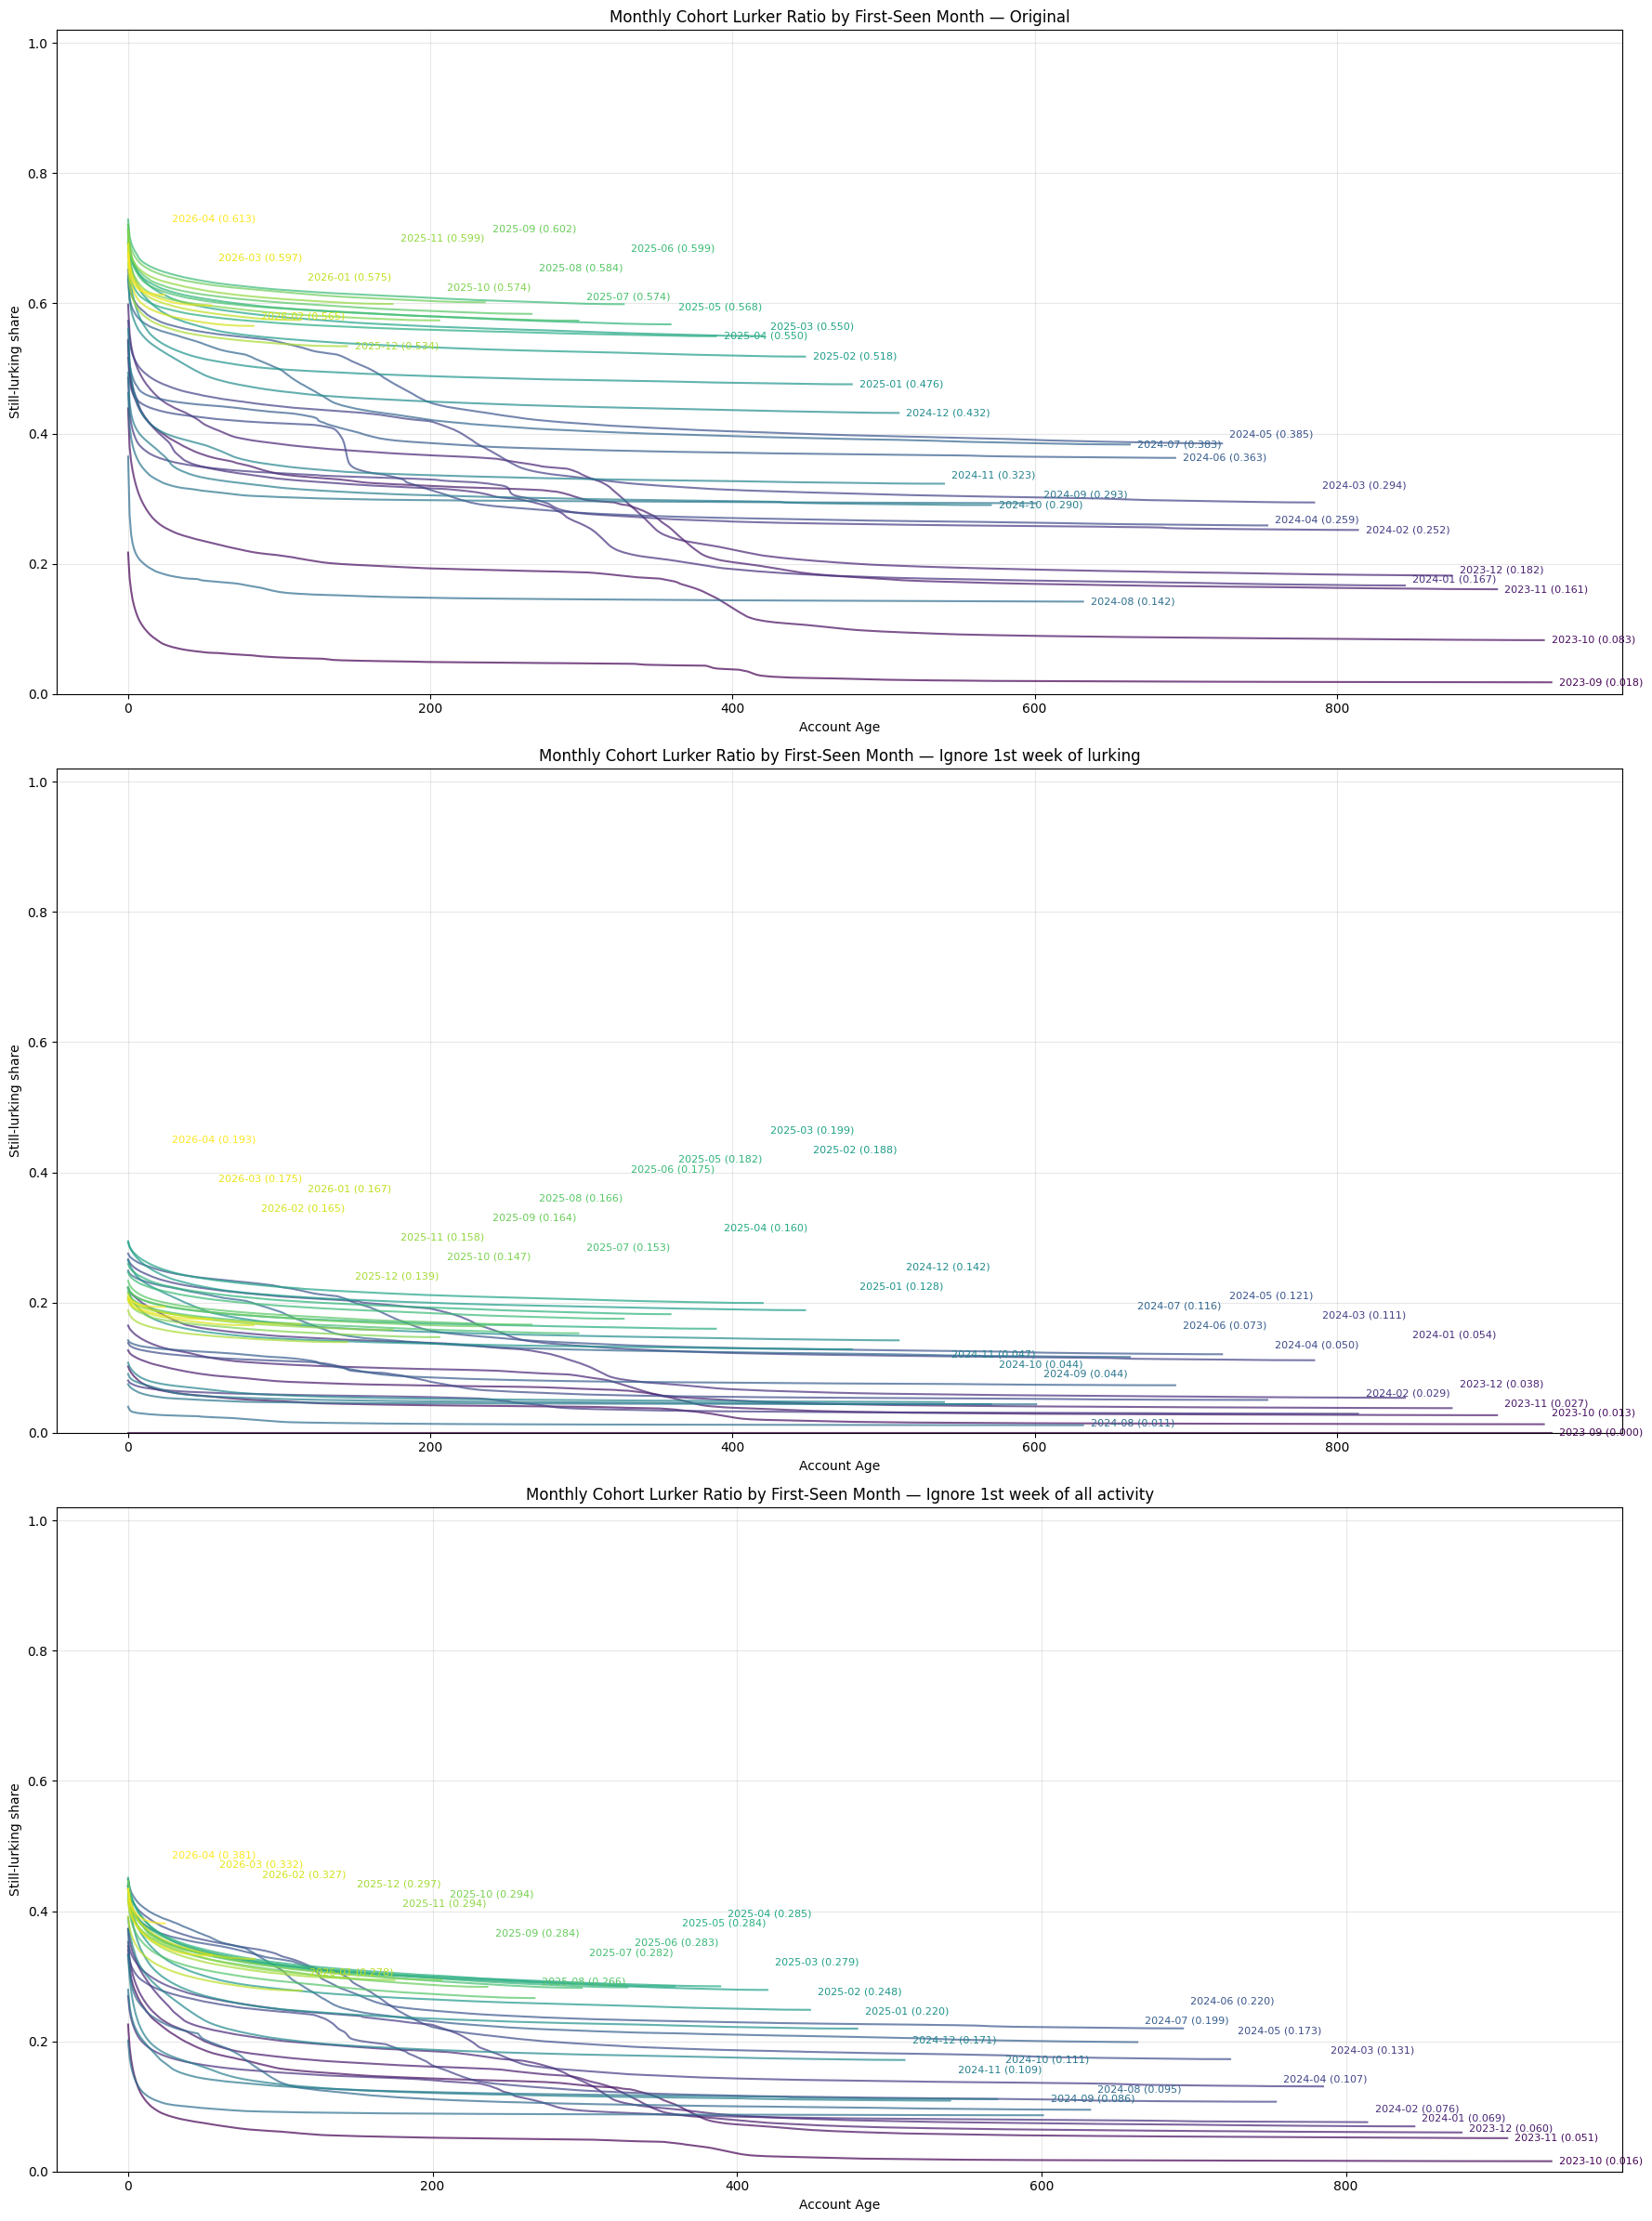

In [3]:
fig, axes = plt.subplots(len(VARIANT_SPECS), 1, figsize=(18, 8 * len(VARIANT_SPECS)), sharex=False)
if len(VARIANT_SPECS) == 1:
    axes = [axes]

for ax, (variant_name, spec) in zip(axes, VARIANT_SPECS.items()):
    suffix = spec["user_suffix"]
    first_seen_col = "first_seen_day" if not suffix else f"first_seen_day{suffix}"
    first_non_col = "first_non_lurker_day" if not suffix else f"first_non_lurker_day{suffix}"
    variant_users = users[users[first_seen_col].notna()].copy()
    variant_users["cohort_month"] = variant_users[first_seen_col].dt.to_period("M")
    all_months = pd.Series(variant_users["cohort_month"].dropna().unique()).sort_values().to_list()
    norm = mcolors.Normalize(vmin=0, vmax=max(len(all_months) - 1, 1))
    cmap = cm.viridis
    cumulative_df = variant_frames[variant_name]["cumulative"]
    label_data = []
    for i, cohort_month in enumerate(all_months):
        cohort = variant_users[variant_users["cohort_month"] == cohort_month].copy()
        if len(cohort) == 0:
            continue
        total_seen_users = len(cohort)
        cohort["days_to_non_lurker"] = (cohort[first_non_col] - cohort[first_seen_col]).dt.days
        max_days = int((cumulative_df["day"].max() - cohort[first_seen_col].min()).days)
        x = np.arange(max_days + 1)
        ratios = []
        for d in x:
            converted_count = ((cohort["days_to_non_lurker"] <= d) & cohort["days_to_non_lurker"].notna()).sum()
            ratios.append((total_seen_users - converted_count) / total_seen_users)
        color = cmap(norm(i))
        ax.plot(x, ratios, color=color, alpha=0.7, linewidth=1.5)
        label_data.append({"x": x[-1], "y": ratios[-1], "text": f"{cohort_month.to_timestamp().strftime('%Y-%m')} ({ratios[-1]:.3f})", "color": color})
    label_data = sorted(label_data, key=lambda d: d["y"])
    for i in range(1, len(label_data)):
        if label_data[i]["y"] - label_data[i - 1]["y"] < 0.015:
            label_data[i]["y"] = label_data[i - 1]["y"] + 0.015
    for item in label_data:
        ax.text(item["x"] + 5, item["y"], item["text"], color=item["color"], fontsize=8, verticalalignment="center")
    ax.set_title(f"Monthly Cohort Lurker Ratio by First-Seen Month — {spec['label']}")
    ax.set_xlabel("Account Age")
    ax.set_ylabel("Still-lurking share")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### 4b) Lurker ratio over time on a fixed set of Active Users

This view uses all Active Users in the loaded user-state table for each variant.
Only the all-users still-lurking curve is shown here.
The earlier eventually-converting-only group and the 0-30 day zoom are intentionally removed.
Days are measured from each user's first Active User date to their first visible qualifying `create` of a post, reply, quote, repost, or like.


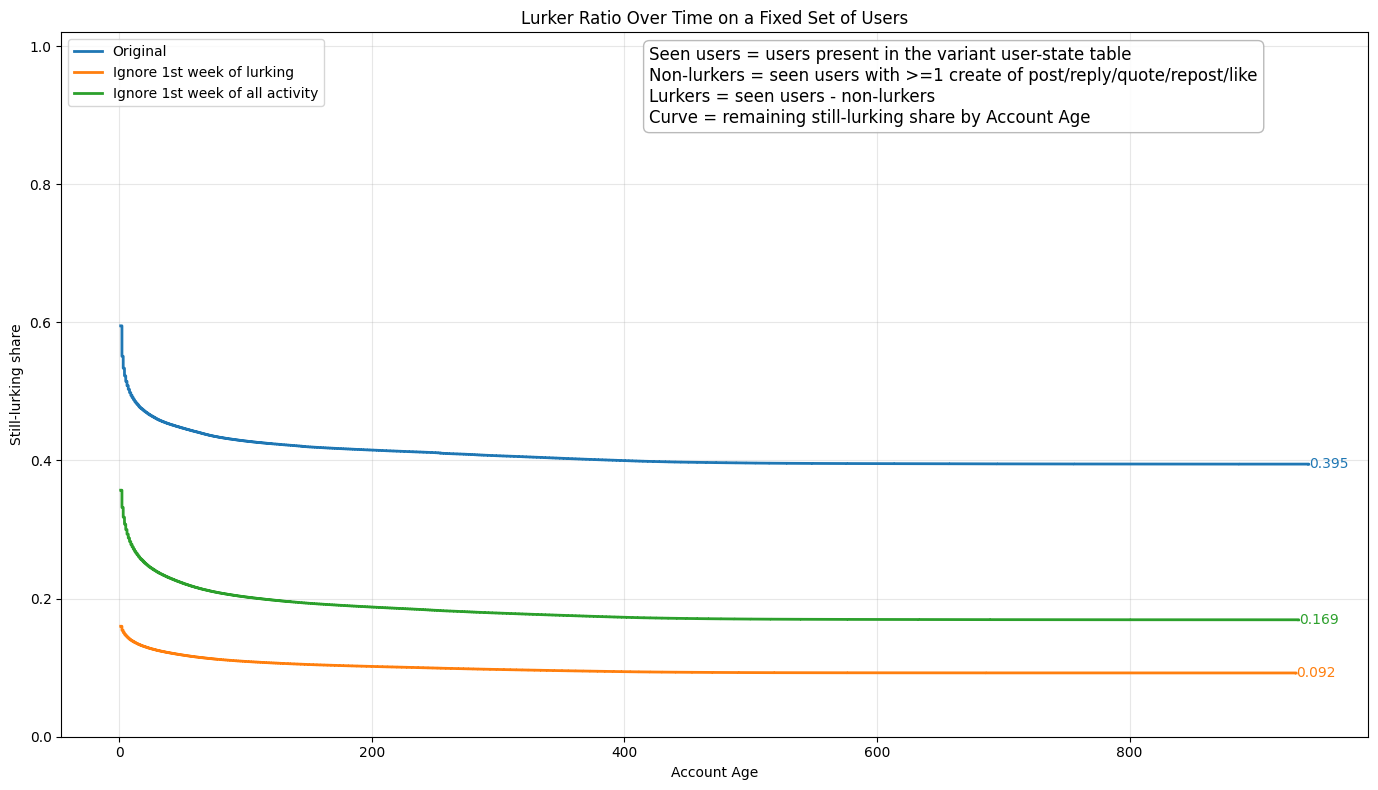

In [4]:
# variable precision
def fmt_pct(y):
    if y == 0:
        return "0"
    elif y < 1e-6:
        return f"{y:.6}"
    elif y < 1e-3:
        return f"{y:.4}"
    return f"{y:.2}"

fig, ax = plt.subplots(figsize=(14, 8))
fixed_count_rows = []
for variant_name, spec in VARIANT_SPECS.items():
    suffix = spec["user_suffix"]
    first_seen_col = "first_seen_day" if not suffix else f"first_seen_day{suffix}"
    first_non_col = "first_non_lurker_day" if not suffix else f"first_non_lurker_day{suffix}"
    variant_users = users[users[first_seen_col].notna()].copy()
    variant_users["days_to_non_lurker"] = (variant_users[first_non_col] - variant_users[first_seen_col]).dt.days
    n_users = len(variant_users)
    converted = variant_users[variant_users["days_to_non_lurker"].notna()].copy()
    if len(converted) == 0:
        continue
    share_by_day = converted["days_to_non_lurker"].astype(int).value_counts().sort_index() / n_users
    remaining = 1 - share_by_day.cumsum()
    ax.step(remaining.index + 1, remaining.values, where="post", linewidth=2, label=spec["label"], color=variant_colors[variant_name])
    final_ratio = float(remaining.iloc[-1]) if len(remaining) else 1.0
    ax.text(int(remaining.index.max()) + 1, final_ratio, f"{final_ratio:.3f}", color=variant_colors[variant_name], fontsize=10, verticalalignment="center")
    seen_users = int(variant_users[first_seen_col].notna().sum())
    non_lurkers = int(variant_users[first_non_col].notna().sum())
    fixed_count_rows.append({
        "Variant": spec["label"],
        "Seen users": seen_users,
        "Non-lurkers": non_lurkers,
        "Lurkers": seen_users - non_lurkers,
        "Final lurker ratio": round((seen_users - non_lurkers) / seen_users, 6) if seen_users else np.nan,
    })
ax.set_title("Lurker Ratio Over Time on a Fixed Set of Users")
ax.set_xlabel("Account Age")
ax.set_ylabel("Still-lurking share")
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.3)
add_definition_box(ax, [
    "Seen users = users present in the variant user-state table",
    "Non-lurkers = seen users with >=1 create of post/reply/quote/repost/like",
    "Lurkers = seen users - non-lurkers",
    "Curve = remaining still-lurking share by Account Age",
], x=0.45, y=0.98)
fig.tight_layout()
plt.show()
fixed_count_table = pd.DataFrame(fixed_count_rows)


In [5]:
fixed_count_table


,Variant,Seen users,Non-lurkers,Lurkers,Final lurker ratio
0,Original,43315383,26216081,17099302,0.394763
1,Ignore 1st week of lurking,28882694,26216081,2666613,0.092326
2,Ignore 1st week of all activity,22503996,18693129,3810867,0.169342


## 4c) Cumulative lurker ratio

This plot uses cumulative counts through day `t`, with one line per prep variant.
- **Numerator**: cumulative Lurkers through day `t`
- **Denominator**: cumulative Active Users through day `t` (implementation column: `seen_users`)
- **Non-Lurker inclusion**: any visible qualifying `create` of a post, reply, quote, repost, or like on or before day `t`


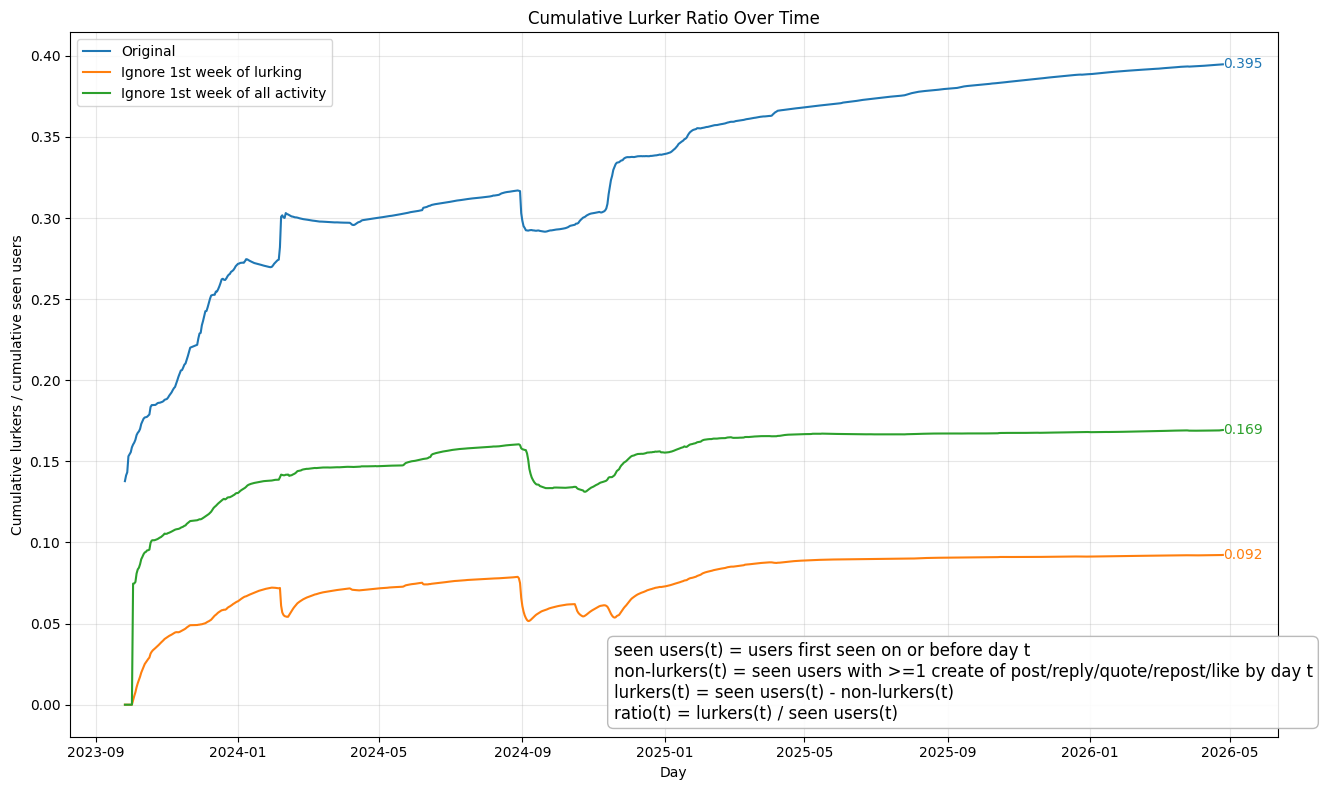

In [6]:
fig, ax = plt.subplots(figsize=(14, 8))
cumulative_count_rows = []
for variant_name, spec in VARIANT_SPECS.items():
    cumulative_df = variant_frames[variant_name]["cumulative"].sort_values("day")
    ax.plot(cumulative_df["day"], cumulative_df["lurker_ratio"], label=spec["label"], color=variant_colors[variant_name])
    last_row = cumulative_df.iloc[-1]
    ax.text(last_row["day"], float(last_row["lurker_ratio"]), f"{float(last_row['lurker_ratio']):.3f}", fontsize=10, verticalalignment="center", color=variant_colors[variant_name])
    cumulative_count_rows.append({
        "Variant": spec["label"],
        "Last day": pd.Timestamp(last_row["day"]).strftime("%Y-%m-%d"),
        "Seen users": int(last_row["seen_users"]),
        "Non-lurkers": int(last_row["non_lurkers"]),
        "Lurkers": int(last_row["lurkers"]),
        "Lurker ratio": round(float(last_row["lurker_ratio"]), 6),
    })
ax.set_title("Cumulative Lurker Ratio Over Time")
ax.set_xlabel("Day")
ax.set_ylabel("Cumulative lurkers / cumulative seen users")
ax.legend()
ax.grid(alpha=0.3)
add_definition_box(ax, [
    "seen users(t) = users first seen on or before day t",
    "non-lurkers(t) = seen users with >=1 create of post/reply/quote/repost/like by day t",
    "lurkers(t) = seen users(t) - non-lurkers(t)",
    "ratio(t) = lurkers(t) / seen users(t)",
], x=0.45, y=0.02, ha="left", va="bottom")
fig.tight_layout()
plt.show()
cumulative_count_table = pd.DataFrame(cumulative_count_rows)


In [7]:
cumulative_count_table


,Variant,Last day,Seen users,Non-lurkers,Lurkers,Lurker ratio
0,Original,2026-04-25,43315383,26216081,17099302,0.394763
1,Ignore 1st week of lurking,2026-04-25,28882694,26216081,2666613,0.092326
2,Ignore 1st week of all activity,2026-04-25,22503996,18693129,3810867,0.169342


## 4d) Sliding window lurker ratio

Each line uses a trailing `W`-day window ending on day `t`, compared across all three variants.
- **Numerator**: window Lurkers in `[t-W+1, t]`
- **Denominator**: window Active Users in `[t-W+1, t]` (implementation column: `seen_users`)
- **Non-Lurker inclusion**: any visible qualifying `create` of a post, reply, quote, repost, or like within `[t-W+1, t]`


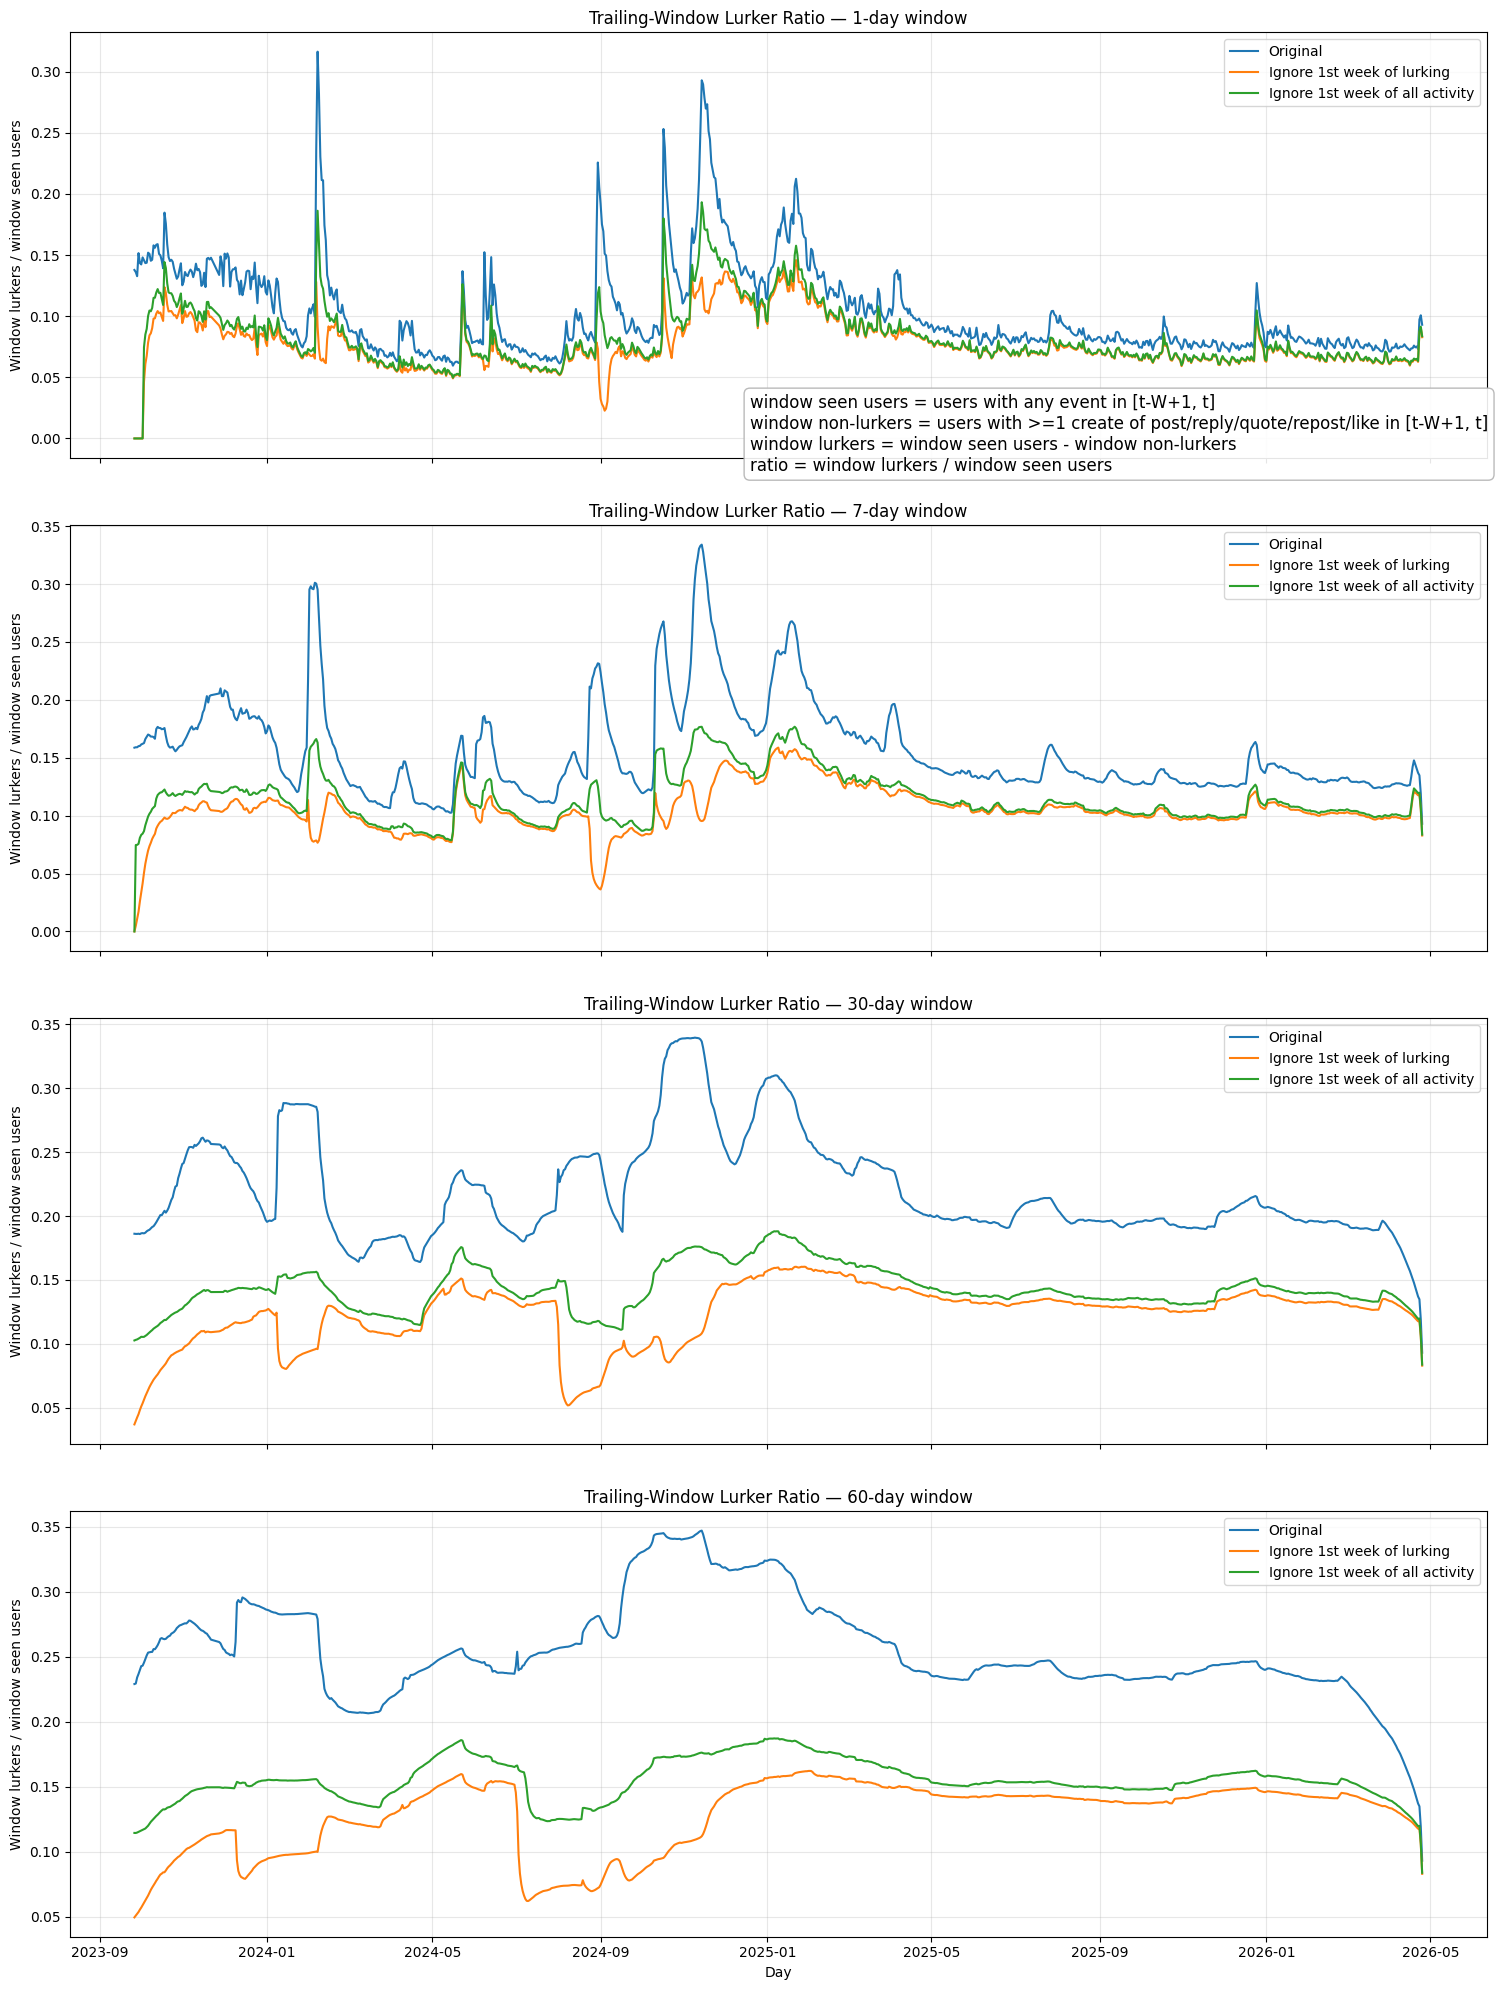

In [8]:
window_values = sorted(daily["window_size"].unique())
fig, axes = plt.subplots(len(window_values), 1, figsize=(16, 5 * len(window_values)), sharex=True)
if len(window_values) == 1:
    axes = [axes]
for ax, w in zip(axes, window_values):
    for variant_name, spec in VARIANT_SPECS.items():
        df = variant_frames[variant_name]["daily"]
        df = df[df["window_size"] == w]
        ax.plot(df["day"], df["lurker_ratio"], label=spec["label"], color=variant_colors[variant_name])
    ax.set_title(f"Trailing-Window Lurker Ratio — {w}-day window")
    ax.set_ylabel("Window lurkers / window seen users")
    ax.grid(alpha=0.3)
    ax.legend()
axes[-1].set_xlabel("Day")
add_definition_box(axes[0], [
    "window seen users = users with any event in [t-W+1, t]",
    "window non-lurkers = users with >=1 create of post/reply/quote/repost/like in [t-W+1, t]",
    "window lurkers = window seen users - window non-lurkers",
    "ratio = window lurkers / window seen users",
], x=0.48, y=0.15, ha="left")
fig.tight_layout()
plt.show()


## 4e) Population growth sanity check

We expect:
- Active Users (`seen_users`) to increase monotonically because a user stays counted once first seen
- Non-Lurkers to increase more slowly than total Active Users
- the gap between the two curves to equal cumulative Lurkers
- the daily-change plot below shows absolute count changes per day, not percentages


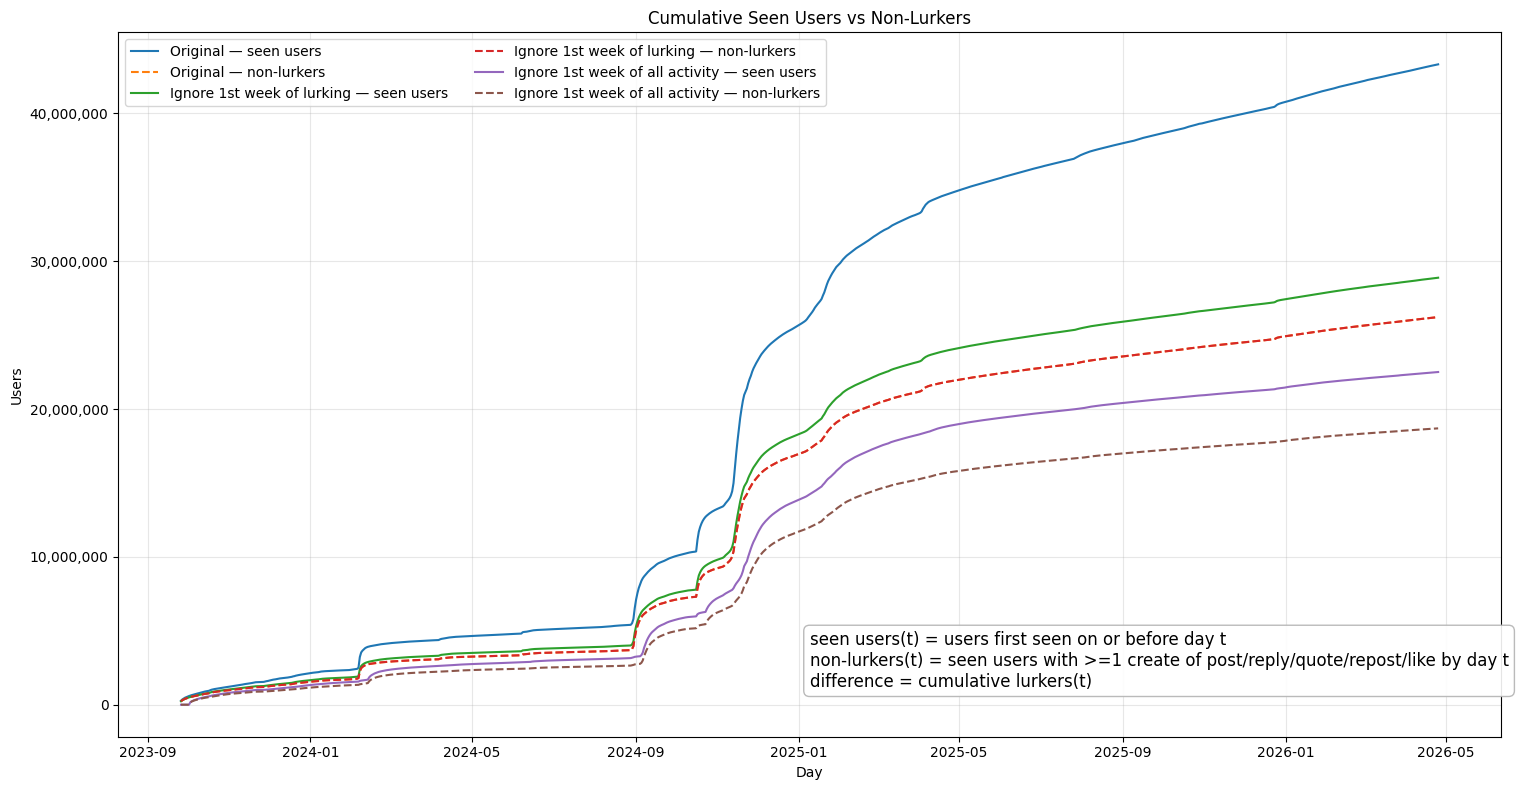

In [9]:
fig, ax = plt.subplots(figsize=(16, 8))
for variant_name, spec in VARIANT_SPECS.items():
    cumulative_df = variant_frames[variant_name]["cumulative"]
    ax.plot(cumulative_df["day"], cumulative_df["seen_users"], label=f"{spec['label']} — seen users", linestyle="-")
    ax.plot(cumulative_df["day"], cumulative_df["non_lurkers"], label=f"{spec['label']} — non-lurkers", linestyle="--")
ax.set_title("Cumulative Seen Users vs Non-Lurkers")
ax.set_xlabel("Day")
ax.set_ylabel("Users")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(ncol=2)
ax.grid(alpha=0.3)
add_definition_box(ax, [
    "seen users(t) = users first seen on or before day t",
    "non-lurkers(t) = seen users with >=1 create of post/reply/quote/repost/like by day t",
    "difference = cumulative lurkers(t)",
], x=0.5, y=0.15, ha="left")
fig.tight_layout()
plt.show()


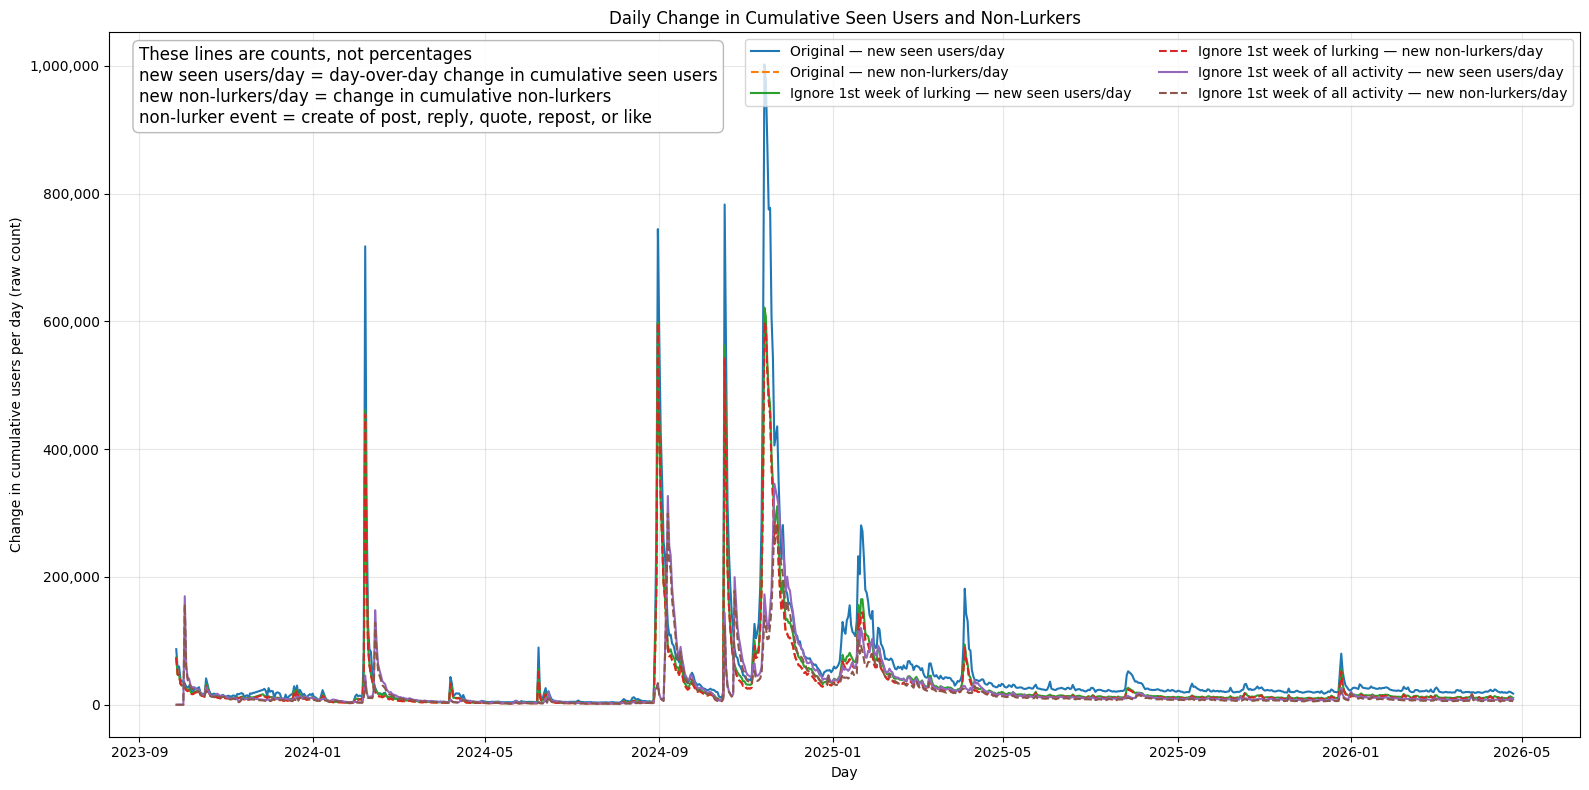

In [10]:
fig, ax = plt.subplots(figsize=(16, 8))
for variant_name, spec in VARIANT_SPECS.items():
    cumulative_df = variant_frames[variant_name]["cumulative"].sort_values("day")
    ax.plot(cumulative_df["day"], cumulative_df["seen_users"].diff(), label=f"{spec['label']} — new seen users/day", linestyle="-")
    ax.plot(cumulative_df["day"], cumulative_df["non_lurkers"].diff(), label=f"{spec['label']} — new non-lurkers/day", linestyle="--")
ax.set_title("Daily Change in Cumulative Seen Users and Non-Lurkers")
ax.set_xlabel("Day")
ax.set_ylabel("Change in cumulative users per day (raw count)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(ncol=2)
ax.grid(alpha=0.3)
add_definition_box(ax, [
    "These lines are counts, not percentages",
    "new seen users/day = day-over-day change in cumulative seen users",
    "new non-lurkers/day = change in cumulative non-lurkers",
    "non-lurker event = create of post, reply, quote, repost, or like",
], x=0.02, y=0.98)
fig.tight_layout()
plt.show()


## 5) Conclusion and default calibration value

The recommended default calibration value is **16.9%** for `user.activity.lurker_sample_rate`.

Interpretation: by default, the simulator should treat **16.9% of Active Users** as **Lurkers**: users who have logged in and performed observed activity, but whose observed activity is not visible to others. The remaining **83.1% of Active Users** are treated as **Non-Lurkers**: users who have performed at least one visible qualifying action such as a post, reply, quote, repost, or like.

This value should be used as the default because it is the report's selected empirical estimate of the ratio:

`Lurkers / Active Users = 16.9%`

If future runs of `lurker_ratio_prep.py` materially change the ratio, this section should be updated together with the default config value.
